# Logistic Regression from Scratch

This notebook makes the main training steps visible: calculate probabilities, measure binary cross-entropy, calculate gradients, and update the weights and bias with gradient descent. The small student table is only for learning the calculations; use a held-out test set for practical evaluation.


## 1. Prepare a small labeled dataset

Each row is one student. The two inputs are study hours and attendance; `passed` is the binary target (`1` = pass, `0` = fail). The inputs are expressed on similar 0-to-1 scales so one feature's units do not dominate the gradient updates.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


students = pd.DataFrame(
    {
        "hours_studied": [1, 2, 2, 3, 5, 6, 8, 9],
        "attendance_pct": [50, 55, 80, 60, 65, 75, 80, 95],
        "passed": [0, 0, 0, 0, 1, 1, 1, 1],
    }
)

features = ["hours_studied", "attendance_pct"]
X = students[features].to_numpy(dtype=float) / np.array([10, 100])
y = students["passed"].to_numpy(dtype=float)

students


,hours_studied,attendance_pct,passed
0,1,50,0
1,2,55,0
2,2,80,0
3,3,60,0
4,5,65,1
5,6,75,1
6,8,80,1
7,9,95,1


## 2. Model and binary cross-entropy

For example $i$, the model computes a score $z^{(i)} = w^T x^{(i)} + b$ and probability $\hat{y}^{(i)} = \sigma(z^{(i)})$. The weights $w$ and bias $b$ are learned from labeled examples.

Binary cross-entropy (log loss) penalizes confident, incorrect probabilities:

$$J(w,b) = -\frac{1}{m}\sum_{i=1}^{m}\left[y^{(i)}\log(\hat{y}^{(i)}) + (1-y^{(i)})\log(1-\hat{y}^{(i)})\right]$$


In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def binary_cross_entropy(y_true, probabilities):
    # Keep logarithm inputs away from zero and one.
    probabilities = np.clip(probabilities, 1e-15, 1 - 1e-15)
    return -np.mean(
        y_true * np.log(probabilities)
        + (1 - y_true) * np.log(1 - probabilities)
    )


## 3. Calculate gradients and update parameters

Gradient descent starts with initial parameters (here, zeros), then repeatedly moves them in the direction that lowers the loss. For logistic regression, the gradients are the average prediction error, weighted by each feature for $w$, and averaged directly for $b$:

$$\frac{\partial J}{\partial w} = \frac{1}{m}X^T(\hat{y}-y), \qquad \frac{\partial J}{\partial b} = \frac{1}{m}\sum_{i=1}^{m}(\hat{y}^{(i)}-y^{(i)})$$

Compute both gradients from the same current predictions, then update all parameters together. A learning rate that is too large can make the loss rise or diverge; one that is too small makes learning slow.


In [3]:
def gradient_descent_step(X, y, weights, bias, learning_rate):
    m = X.shape[0]
    probabilities = sigmoid(X @ weights + bias)
    errors = probabilities - y

    weight_gradient = X.T @ errors / m
    bias_gradient = errors.mean()

    weights = weights - learning_rate * weight_gradient
    bias = bias - learning_rate * bias_gradient
    return weights, bias


## 4. Train and inspect the learning curve

Repeat the gradient update for a fixed number of iterations and record the loss. A steadily falling training loss shows that these updates are learning on this small example; it is not evidence that a model will generalize to new data.


Initial loss: 0.693
Final loss: 0.250
Weights: [5.70923549 0.31477878]
Bias: -2.5981602971039397


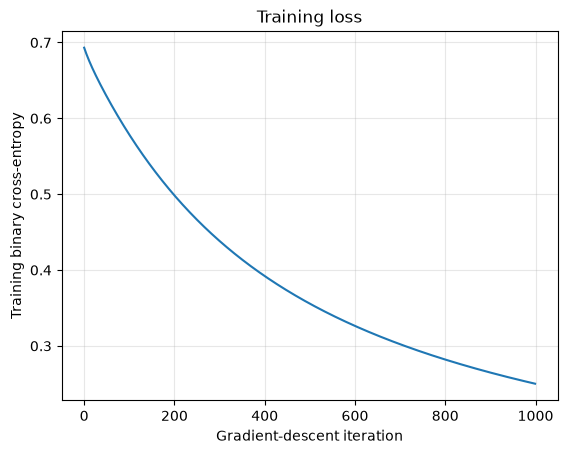

In [4]:
weights = np.zeros(X.shape[1])
bias = 0.0
learning_rate = 0.1
loss_history = []

for _ in range(1000):
    probabilities = sigmoid(X @ weights + bias)
    loss_history.append(binary_cross_entropy(y, probabilities))
    weights, bias = gradient_descent_step(
        X, y, weights, bias, learning_rate
    )

final_probabilities = sigmoid(X @ weights + bias)
final_loss = binary_cross_entropy(y, final_probabilities)

print(f"Initial loss: {loss_history[0]:.3f}")
print(f"Final loss: {final_loss:.3f}")
print("Weights:", weights)
print("Bias:", bias)

plt.plot(loss_history)
plt.xlabel("Gradient-descent iteration")
plt.ylabel("Training binary cross-entropy")
plt.title("Training loss")
plt.grid(alpha=0.3)
plt.show()


## 5. Predict probabilities and labels

The model output is a probability for class 1. The default 0.5 threshold turns it into a label; later lessons evaluate those labels and discuss when a different threshold is appropriate.


In [5]:
predictions = students[features].copy()
predictions["actual_passed"] = y.astype(int)
predictions["probability_passed"] = final_probabilities
predictions["predicted_passed"] = (final_probabilities >= 0.5).astype(int)

predictions


,hours_studied,attendance_pct,actual_passed,probability_passed,predicted_passed
0,1,50,0,0.133559,0
1,2,55,0,0.217009,0
2,2,80,0,0.230677,0
3,3,60,0,0.332584,0
4,5,65,1,0.613266,1
5,6,75,1,0.743352,1
6,8,80,1,0.902124,1
7,9,95,1,0.944757,1
